<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Standard%20Problem%204_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Mumax⁺ in Google Colaboratory**

# About Google Colaboratory

Google Colaboratory is a research tool mainly used by researchers in the field of machine learning. The main purpose of this tool is to run Python code in Jupyter notebooks. These notebooks run on a virtual Linux machine private to your Gmail account. This means that you will need a Gmail account to execute programs in a Google Colaboratory session. If you have a Gmail account you should be able to copy this Jupyter notebook to your Google Drive and execute the code cells.

Run the cell below to connect to a GPU-enabled Colaboratory runtime and display its details.

In [1]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

This machine runs Linux with Python 3.13.16 and provides the following GPU/CUDA specs:
Sun Nov  8 19:47:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |          

# Installing mumax⁺

To run mumax⁺ simulations, the `mumaxplus` Python package must be installed in this Colab environment. To this end, we will make our life easy by using the appropriate pre-built wheel provided in the mumax⁺ GitHub release assets. Running the cell below will install mumax⁺, which may take a minute to complete. When the installation is done, you can collapse this section to get a clean workspace.

In [2]:
try:
    import google.colab
except ImportError:
    pass
else:
    !uv pip install mumaxplus

Using Python 3.13.16 environment at: /usr
Resolved 15 packages in 1.25s
Prepared 2 packages in 8.20s
Installed 2 packages in 2ms
 + mumaxplus==1.2.2
 + pyovf==0.3.0


# Running mumax+

Now it's up to you! The example below solves Standard Problem 4 using mumax⁺, but feel free to create a copy of this notebook to solve another micromagnetic problem of your choice.

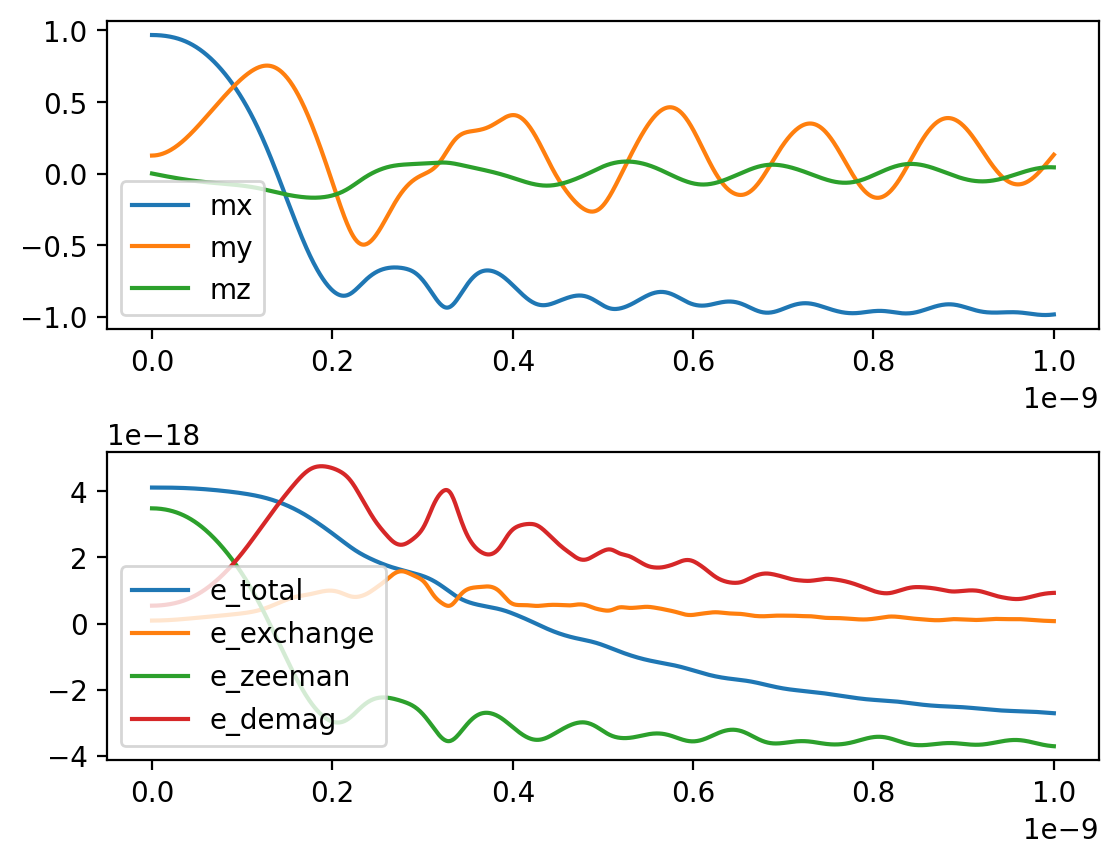

In [3]:
# This script solves micromagnetic Standard Problem 4. The Problem specification
# can be found on https://www.ctcms.nist.gov/~rdm/mumag.org.html

import matplotlib.pyplot as plt
import numpy as np

from mumaxplus import Ferromagnet, Grid, World

plt.rcParams['figure.dpi'] = 200

length, width, thickness = 500e-9, 125e-9, 3e-9
nx, ny, nz = 128, 32, 1
world = World(cellsize=(length / nx, width / ny, thickness / nz))

magnet = Ferromagnet(world, Grid((nx, ny, nz)))
magnet.msat = 800e3
magnet.aex = 13e-12
magnet.alpha = 0.02

magnet.magnetization = (1, 0.1, 0)
magnet.minimize()

B1 = (-24.6e-3, 4.3e-3, 0)
B2 = (-35.5e-3, -6.3e-3, 0)
world.bias_magnetic_field = B1  # choose B1 or B2 here

# --- SCHEDULE THE OUTPUT ---
timepoints = np.linspace(0, 1e-9, 1000)
outputquantities = {
    "mx": lambda: magnet.magnetization.average()[0],
    "my": lambda: magnet.magnetization.average()[1],
    "mz": lambda: magnet.magnetization.average()[2],
    "e_total": magnet.total_energy,
    "e_exchange": magnet.exchange_energy,
    "e_zeeman": magnet.zeeman_energy,
    "e_demag": magnet.demag_energy
}

# --- RUN THE SOLVER ---
output = world.timesolver.solve(timepoints, outputquantities)

# --- PLOT THE OUTPUT DATA ---
plt.subplot(211)
for key in ["mx", "my", "mz"]:
    plt.plot(output["time"], output[key], label=key)
plt.legend()

plt.subplot(212)
for key in ["e_total", "e_exchange", "e_zeeman", "e_demag"]:
    plt.plot(timepoints, output[key], label=key)
plt.legend()

plt.subplots_adjust(hspace=0.4)
plt.show()

In [ ]:
import gc
from io import BytesIO

from IPython.display import Image as DisplayImage, display
from PIL import GifImagePlugin, Image as PILImage
from mumaxplus.util import plot_field

GIF_FPS = 12

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.weight": "normal",
    "axes.titleweight": "normal",
})

# --- Replay the selected field case ---
selected_field = tuple(world.bias_magnetic_field)
world.bias_magnetic_field = (0, 0, 0)
world.timesolver.time = 0
magnet.magnetization = (1, 0.1, 0)
magnet.minimize()
world.bias_magnetic_field = selected_field
world.timesolver.time = 0

# --- Create heatmaps and bounded glyphs once ---
fig, axes = plt.subplots(3, 1, figsize=(10, 9), dpi=250)
fig.subplots_adjust(left=0.09, right=0.90, bottom=0.07, top=0.92, hspace=0.55)
images, glyphs = [], []
field = np.asarray(magnet.magnetization.eval(), dtype=np.float32)

for component, ax in enumerate(axes):
    plot_field(
        magnet.magnetization,
        field=field,
        ax=ax,
        component=component,
        title=rf"$m_{{{'xyz'[component]}}}$",
        enable_colorbar=False,
        enable_quiver=True,
        arrow_size=1,
        imshow_kwargs={
            "cmap": "RdBu_r", "vmin": -1, "vmax": 1,
            "interpolation": "nearest",
        },
        quiver_kwargs={
            "angles": "xy", "scale_units": "xy",
            "scale": 1 / (0.75 * min(world.cellsize[:2])),
            "units": "xy", "width": 0.06 * min(world.cellsize[:2]),
            "pivot": "middle", "headwidth": 3, "headlength": 4,
            "headaxislength": 3.5, "minlength": 0,
            "color": "black", "alpha": 0.85, "linewidth": 0,
        },
    )
    ax.set_aspect("equal")
    images.append(ax.images[-1])
    glyphs.append(ax.collections[-1])

del field
timestamp = fig.text(0.5, 0.97, "", ha="center", weight="normal")

fig.colorbar(
    axes[0].images[0], ax=axes.tolist(), fraction=0.025, pad=0.025,
    label="Normalized magnetization component",
)

# --- Use one fixed 8-bit palette for every GIF frame ---
palette_rgb = np.vstack((
    255 * plt.get_cmap("RdBu_r")(np.linspace(0, 1, 224))[:, :3],
    np.repeat(np.linspace(0, 255, 32)[:, None], 3, axis=1),
)).round().astype(np.uint8)
palette = PILImage.new("P", (1, 1))
palette.putpalette(palette_rgb.ravel().tolist())
gif_buffer = BytesIO()
frame_times = np.linspace(0, timepoints[-1], 101)

# --- Process eight snapshots at a time and stream encoded frames ---
for start in range(0, len(frame_times), 8):
    batch = world.timesolver.solve(
        frame_times[start:start + 8], {"m": magnet.magnetization},
    )

    for offset, (frame_time, field) in enumerate(
        zip(batch["time"], batch["m"])
    ):
        frame_index = start + offset
        field = np.asarray(field, dtype=np.float32)

        for component, (image, glyph) in enumerate(zip(images, glyphs)):
            image.set_data(field[component, 0])
            glyph.set_UVC(field[0, 0], field[1, 0])

        timestamp.set_text(
            f"Standard Problem 4: t = {frame_time * 1e9:.3f} ns"
        )
        fig.canvas.draw()

        with PILImage.fromarray(
            np.asarray(fig.canvas.buffer_rgba())[:, :, :3]
        ) as rgb:
            gif_frame = rgb.quantize(
                palette=palette, dither=PILImage.Dither.NONE,
            )

        if frame_index == 0:
            for block in GifImagePlugin.getheader(
                gif_frame, info={"loop": 0, "optimize": False},
            )[0]:
                gif_buffer.write(block)

        # GIF delays use 10 ms units; alternate delays to average 12 FPS.
        delay_ms = 10 * (
            round((frame_index + 1) * 100 / GIF_FPS)
            - round(frame_index * 100 / GIF_FPS)
        )
        for block in GifImagePlugin.getdata(
            gif_frame, duration=delay_ms, disposal=1,
        ):
            gif_buffer.write(block)

        gif_frame.close()
        del gif_frame

    # Release CPU snapshots; mumaxplus manages its own CUDA memory pool.
    del batch, field
    gc.collect()

# --- Display the in-memory GIF with automatic, infinite replay ---
gif_buffer.write(b";")
gif_bytes = gif_buffer.getvalue()
gif_buffer.close()
plt.close(fig)
palette.close()
del fig, axes, ax, images, glyphs, image, glyph, timestamp, palette
gc.collect()

display(DisplayImage(data=gif_bytes, format="gif"))

### Snapshot of the initialized state.

(After running the code, the animation will play automatically)

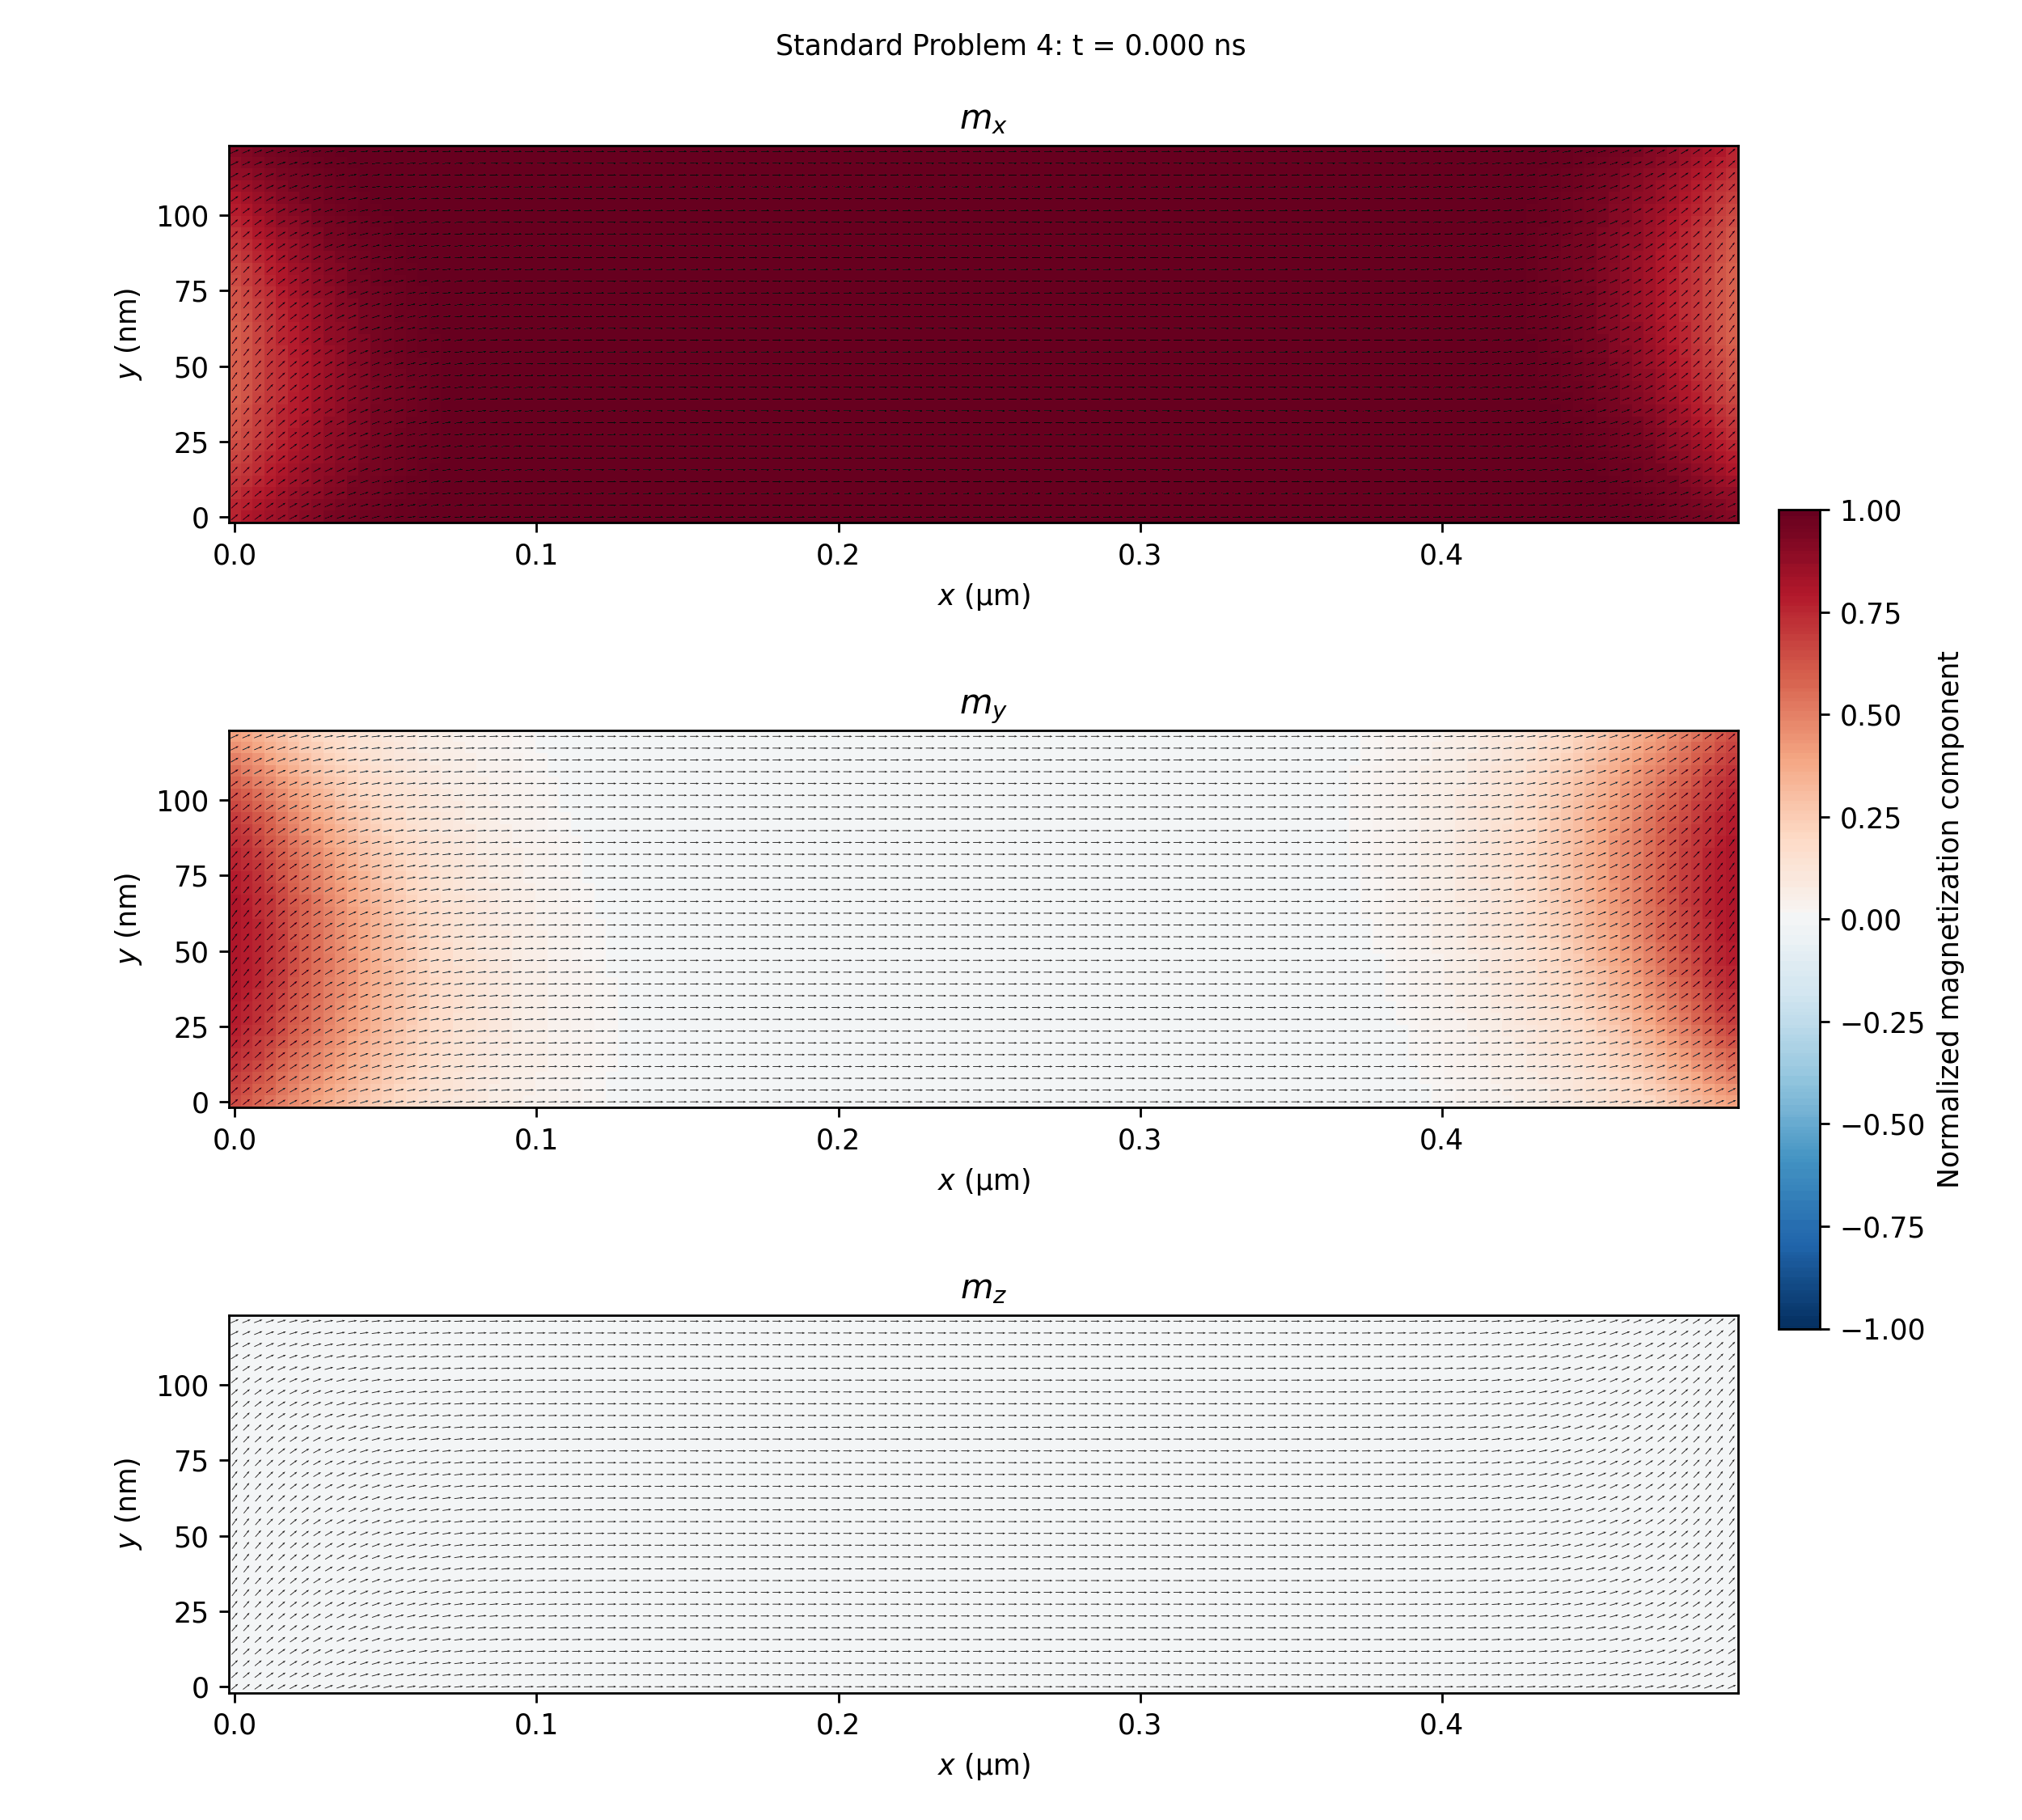